# Part 6: COVID-19 Case Study

## Connecting Theory to Real-World Pandemic Modelling

---

## Goal

Connect everything we've built to **real-world** epidemic modelling.

So far we've developed a hierarchy of models:

```
SIR  →  SEIR  →  Network SIR  →  Degree-Based  →  ABM
```

Each added realism by relaxing an assumption. Now we ask:

> **How were these ideas actually used during the COVID-19 pandemic?**

This notebook is interpretive — light on new code, focused on connecting
theory to practice. We'll reproduce three illustrative figures and map each
model in our hierarchy to a piece of real COVID-19 research.

## Setup

In [2]:
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt

from sir import simulate_sir
from utils import compute_R0

np.random.seed(42)
plt.rcParams['figure.dpi'] = 100
print("✓ Setup complete")

✓ Setup complete


## 6.1 Why COVID-19 Was Different

Real pandemics break the clean assumptions of textbook models. COVID-19
stressed four of them in particular.

### Latency
A long incubation period (≈2–14 days) and **pre-symptomatic transmission**
meant people spread the virus before feeling sick. This is exactly the gap
between *infected* and *infectious* that the **SEIR** model captures with its
Exposed compartment.

### Mobility
Global air travel seeded outbreaks across continents within weeks. Local
movement (commuting, shopping) drove community spread. Mobility is a
**network / spatial** phenomenon — homogeneous mixing cannot represent it.

### Behaviour
People changed behaviour in response to the epidemic: distancing, masking,
working from home. Interventions like lockdowns effectively **reduced β**
over time, something a constant-parameter SIR model cannot do on its own.

### Heterogeneity
Transmission was highly over-dispersed: a small fraction of cases
(super-spreader events) drove most infections. This is the **degree
heterogeneity** of scale-free contact networks — a few high-degree hubs
dominate.

## 6.2 The Imperial College Model

One of the most influential early models was the Imperial College London
report (Ferguson et al., March 2020). It is a useful example because it
**combined every layer** we have studied:

| Layer | What it added | Our notebook |
|-------|---------------|--------------|
| Compartments (SEIR+) | Exposed, hospitalised, ICU, dead | Parts 1–2 |
| Age structure | Age-specific severity & contacts | — |
| Contact networks | Household / school / workplace / community | Part 3 |
| Heterogeneity | Different contact intensities | Part 4 |
| Spatial ABM | 30M+ individual agents on a UK map | Part 5 |
| Interventions | Case isolation, distancing, school closure, lockdown | This part |

### Main ideas

1. **Mitigation vs. suppression** — slowing the epidemic versus driving R below 1.
2. **Healthcare capacity** — the key constraint was ICU beds, not just total cases.
3. **"Flatten the curve"** — interventions lower and delay the peak so demand
   stays under capacity.

The figures below illustrate these ideas using the simple SIR engine we
already built — the *concepts* transfer even though the real model was far
larger.

## Figure 26: COVID-19 Waves and Interventions

Real epidemics arrive in **waves**: an intervention pushes R below 1, cases
fall, restrictions relax, R rises again, and a new wave begins — often with a
more transmissible variant. We reproduce this qualitatively by running SIR
over successive intervals with a changing β (a simple time-dependent R).

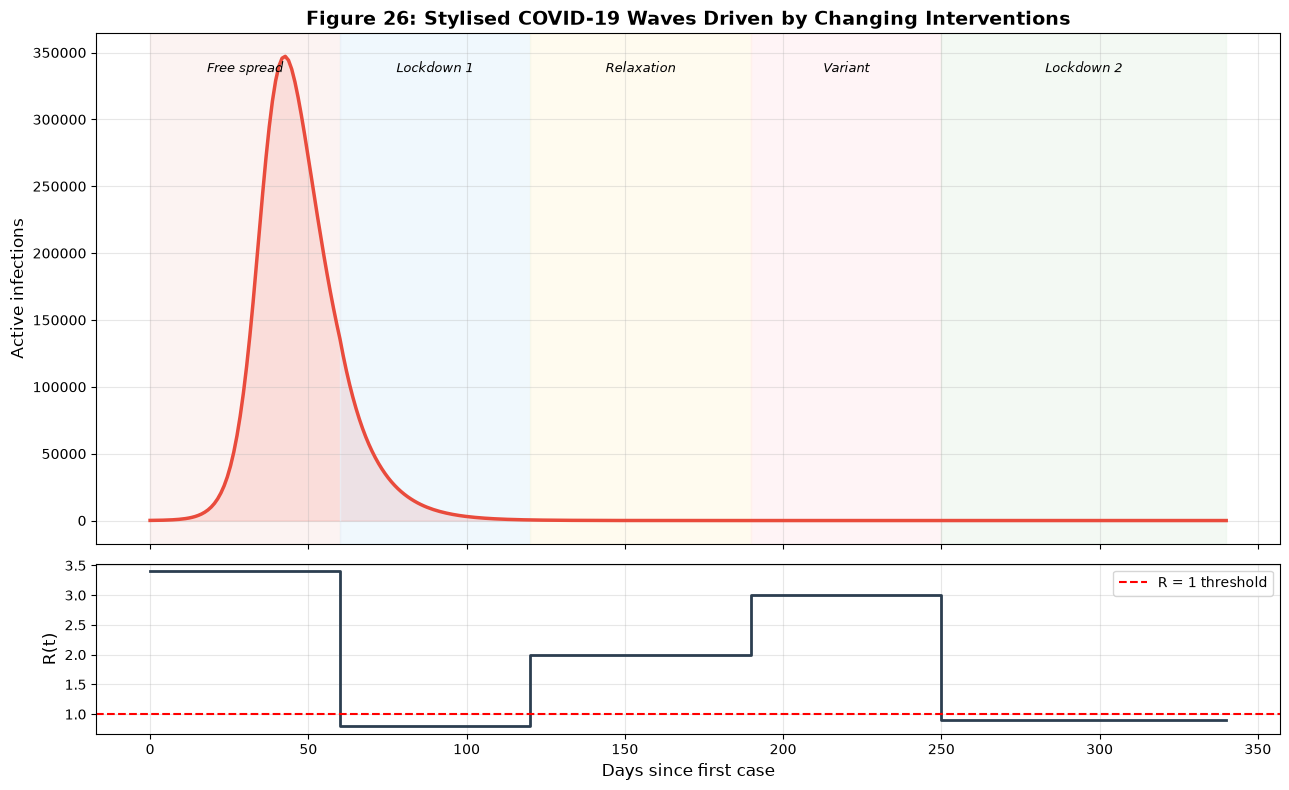

Each wave grows while R > 1 and recedes once an intervention pushes R < 1.
A more transmissible variant raises R even without behaviour change.


In [3]:
# Piecewise time-varying transmission: each phase has its own beta (=> R0)
gamma = 0.1
N = 1_000_000

# (duration_days, beta) for each phase: free spread -> lockdown -> relax -> variant -> control
phases = [
    (60, 0.34),   # initial free spread (R0=3.4)
    (60, 0.08),   # lockdown 1 (R0=0.8)
    (70, 0.20),   # relaxation (R0=2.0)
    (60, 0.30),   # more transmissible variant (R0=3.0)
    (90, 0.09),   # lockdown 2 / control (R0=0.9)
]

# Integrate SIR phase by phase, carrying the state forward
S, I, R = N - 100, 100, 0
t_all, I_all, beta_all = [], [], []
t0 = 0
for dur, beta in phases:
    sol = simulate_sir(beta, gamma, S, I, R, t_span=(0, dur),
                       t_eval=np.linspace(0, dur, dur))
    t_all.append(sol.t + t0)
    I_all.append(sol.y[1])
    beta_all.append(np.full_like(sol.t, beta))
    S, I, R = sol.y[0][-1], sol.y[1][-1], sol.y[2][-1]
    t0 += dur

t = np.concatenate(t_all)
I_t = np.concatenate(I_all)
beta_t = np.concatenate(beta_all)
R_t = beta_t / gamma  # effective reproduction number (S~N early)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(t, I_t, linewidth=2.5, color='#E94B3C')
ax1.fill_between(t, 0, I_t, alpha=0.25, color='#E94B3C')
ax1.set_ylabel('Active infections', fontsize=12)
ax1.set_title('Figure 26: Stylised COVID-19 Waves Driven by Changing Interventions',
              fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Shade phases and label
labels = ['Free spread', 'Lockdown 1', 'Relaxation', 'Variant', 'Lockdown 2']
edges = np.cumsum([0] + [d for d, _ in phases])
colors = ['#FBE9E7', '#E3F2FD', '#FFF8E1', '#FFEBEE', '#E8F5E9']
for i, lab in enumerate(labels):
    ax1.axvspan(edges[i], edges[i+1], alpha=0.5, color=colors[i])
    ax1.text((edges[i]+edges[i+1])/2, ax1.get_ylim()[1]*0.92, lab,
             ha='center', fontsize=9, style='italic')

# R(t) panel
ax2.plot(t, R_t, linewidth=2, color='#2C3E50', drawstyle='steps-post')
ax2.axhline(1.0, color='red', linestyle='--', linewidth=1.5, label='R = 1 threshold')
ax2.set_ylabel('R(t)', fontsize=12)
ax2.set_xlabel('Days since first case', fontsize=12)
ax2.legend(fontsize=10, loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Each wave grows while R > 1 and recedes once an intervention pushes R < 1.")
print("A more transmissible variant raises R even without behaviour change.")

## Figure 27: Mobility Reduction and "Flattening the Curve"

Lockdowns and distancing work by **cutting contacts**, which lowers the
effective transmission rate β. Mobility-tracking datasets (Google/Apple
mobility reports, transit data) were used as real-time proxies for this β
reduction. Here we show how different levels of mobility reduction reshape a
single wave relative to a fixed healthcare capacity.

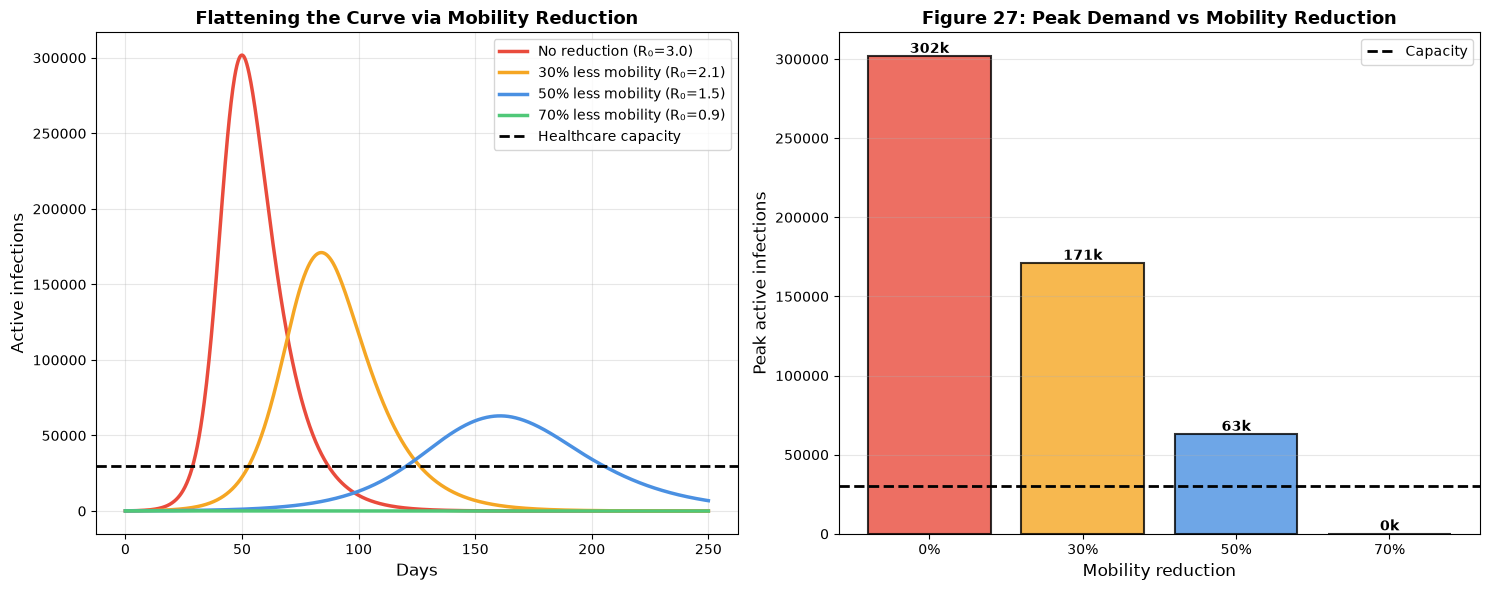

Modest mobility cuts dramatically lower and delay the peak.
Only sufficient reduction keeps peak demand below healthcare capacity.


In [4]:
gamma = 0.1
N = 1_000_000
beta0 = 0.30  # baseline R0 = 3.0

# Each scenario reduces contacts (and thus beta) by a fraction
reductions = [0.0, 0.3, 0.5, 0.7]
labels = ['No reduction', '30% less mobility', '50% less mobility', '70% less mobility']
colors = ['#E94B3C', '#F5A623', '#4A90E2', '#50C878']
capacity = 30000  # stylised ICU/healthcare capacity

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

peaks = []
for red, lab, c in zip(reductions, labels, colors):
    beta = beta0 * (1 - red)
    sol = simulate_sir(beta, gamma, N - 100, 100, 0, t_span=(0, 250))
    ax1.plot(sol.t, sol.y[1], linewidth=2.5, color=c,
             label=f'{lab} (R₀={compute_R0(beta, gamma):.1f})')
    peaks.append(sol.y[1].max())

ax1.axhline(capacity, color='black', linestyle='--', linewidth=2,
            label='Healthcare capacity')
ax1.set_xlabel('Days', fontsize=12)
ax1.set_ylabel('Active infections', fontsize=12)
ax1.set_title('Flattening the Curve via Mobility Reduction', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Peak height vs reduction
bars = ax2.bar([f'{int(r*100)}%' for r in reductions], peaks, color=colors,
               alpha=0.8, edgecolor='black', linewidth=1.5)
ax2.axhline(capacity, color='black', linestyle='--', linewidth=2, label='Capacity')
ax2.set_xlabel('Mobility reduction', fontsize=12)
ax2.set_ylabel('Peak active infections', fontsize=12)
ax2.set_title('Figure 27: Peak Demand vs Mobility Reduction', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, peaks):
    ax2.text(bar.get_x() + bar.get_width()/2, val, f'{val/1000:.0f}k',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print("Modest mobility cuts dramatically lower and delay the peak.")
print("Only sufficient reduction keeps peak demand below healthcare capacity.")

## 6.3 Mobility Networks

Real models replaced "homogeneous mixing" with **mobility networks** built
from data:

- **Nodes** = regions (cities, census areas, countries).
- **Edges** = movement flows between them (commuting, flights), weighted by
  passenger volume.

Disease is simulated *within* each node (a local SIR/SEIR) and *between* nodes
along the weighted edges — a **metapopulation** model. This is the Part 3
network idea applied at the scale of geography rather than individuals, and it
explains why early COVID-19 spread tracked the global air-travel network so
closely.

## 6.4 Agent-Based COVID Models

For fine-grained policy questions, groups built **large-scale agent-based
models** (e.g. CovaSim, OpenABM, the Imperial microsimulation) that simulate
tens of millions of individual agents:

- Each agent has age, household, school, workplace, and location.
- Contacts occur across multiple **network layers** simultaneously.
- Interventions act on specific layers — *school closure* removes the school
  layer; *work-from-home* thins the workplace layer; *case isolation* removes
  an infected agent's edges.

This is exactly the Part 5 ABM, scaled up and given realistic network layers
instead of random spatial motion. The cost is enormous computation; the payoff
is the ability to evaluate concrete, targeted policies.

## 6.5 Mapping Our Models to COVID-19 Research

Every model in this project corresponds to a real piece of pandemic modelling:

| Our model | COVID-19 role |
|-----------|---------------|
| **SIR** | Public communication of R₀ and "flatten the curve" |
| **SEIR** | Incubation & pre-symptomatic transmission; contact-tracing windows |
| **Network SIR** | Contact tracing, super-spreader / cluster analysis |
| **Degree-Based** | Risk stratification (health & essential workers, hubs) |
| **ABM** | Policy evaluation: school closures, lockdown timing, vaccination |
| **Metapopulation / mobility** | Geographic spread, travel restrictions |

The figure below summarises the hierarchy and the feature each level adds.

## Figure 28: Model Hierarchy Roadmap

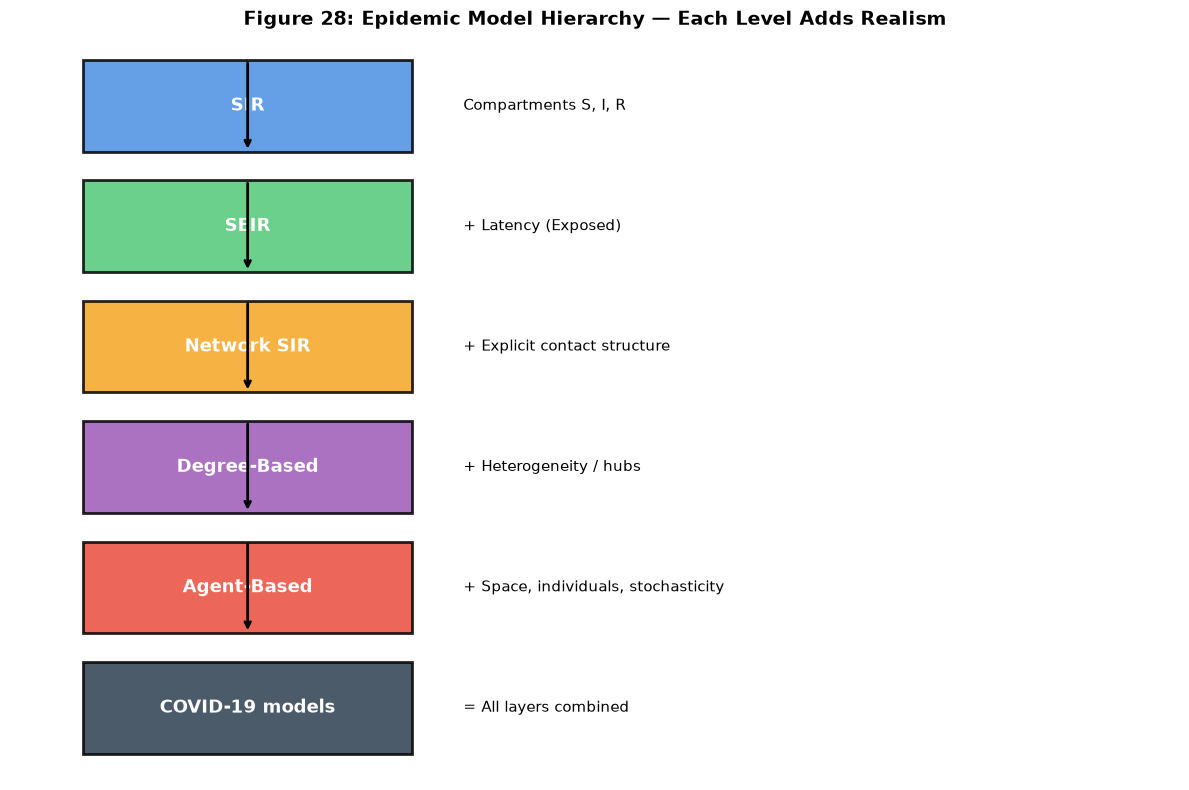

Real pandemic models sit at the bottom: they fuse every layer above.


In [5]:
fig, ax = plt.subplots(figsize=(12, 8))

models = [
    ('SIR',            'Compartments S, I, R',                 '#4A90E2'),
    ('SEIR',           '+ Latency (Exposed)',                  '#50C878'),
    ('Network SIR',    '+ Explicit contact structure',         '#F5A623'),
    ('Degree-Based',   '+ Heterogeneity / hubs',               '#9B59B6'),
    ('Agent-Based',    '+ Space, individuals, stochasticity',  '#E94B3C'),
    ('COVID-19 models','= All layers combined',                '#2C3E50'),
]

n = len(models)
for i, (name, feat, color) in enumerate(models):
    y = n - 1 - i
    box = plt.Rectangle((0.1, y + 0.12), 0.45, 0.76, facecolor=color,
                        edgecolor='black', linewidth=2, alpha=0.85)
    ax.add_patch(box)
    ax.text(0.325, y + 0.5, name, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white')
    ax.text(0.62, y + 0.5, feat, ha='left', va='center', fontsize=11)
    if i < n - 1:
        ax.annotate('', xy=(0.325, y + 0.12), xytext=(0.325, y - 0.12 + 1),
                    arrowprops=dict(arrowstyle='->', lw=2, color='black'))

ax.set_xlim(0, 1.6)
ax.set_ylim(-0.1, n)
ax.axis('off')
ax.set_title('Figure 28: Epidemic Model Hierarchy — Each Level Adds Realism',
             fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print("Real pandemic models sit at the bottom: they fuse every layer above.")

## Summary & Learning Outcome

### What this case study showed

- **COVID-19 broke the simple assumptions**: latency, mobility, behaviour, and
  heterogeneity all mattered at once.
- **No single model was enough.** Real efforts combined SEIR compartments, age
  structure, contact networks, mobility/metapopulation layers, and agent-based
  microsimulation.
- **Interventions = changing parameters.** Lockdowns and distancing act by
  lowering β over time, producing waves (Figure 26) and flattening peaks
  relative to healthcare capacity (Figure 27).
- **Our hierarchy is the real hierarchy** (Figure 28): each model we built maps
  directly onto a tool used in the pandemic response.

### The core takeaway

> Real epidemic models combine multiple modelling layers — and every layer is
> one of the steps we built in Parts 1–5.

Simple models remain valuable for intuition and communication; complex models
are needed for detailed, data-driven policy decisions. Choosing the right level
of the hierarchy for the question at hand is the modeller's real skill.

---

**Continue to Notebook 07: Conclusion** for the final synthesis. →